In [ ]:
TF_ENABLE_ONEDNN_OPTS=0

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
!cp '/content/drive/MyDrive/Nisar_work/DMID_Kaggle.zip' '/content/'
!unzip '/content/DMID_Kaggle.zip' -d '/content/' &> /dev/null
os.remove('/content/DMID_Kaggle.zip')

In [ ]:

import os
!pip install keras-preprocessing
!pip install scikit-image
import tensorflow as tf
import time
#import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("ggplot")
%matplotlib inline

#from tqdm import tqdm_notebook, tnrange
from itertools import chain
# from skimage.io import imread, imshow, concatenate_images
# from skimage.transform import resize
# from skimage.morphology import label
from sklearn.model_selection import train_test_split
# import imageio

from keras.models import Model, load_model
from keras.layers import Input, BatchNormalization, Activation, Dense, Dropout, Resizing
from keras.layers import Lambda, RepeatVector, Reshape
from keras.layers import Conv2D, Conv2DTranspose
from keras.layers import MaxPooling2D, GlobalMaxPool2D, AveragePooling2D
from keras.regularizers import l2
#from keras.layers.merge import concatenate, add
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from keras.optimizers import Adam
#from keras_preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img
from keras.models import *
from keras.layers import *
from keras.optimizers import *
from keras.callbacks import *
from keras.losses import *
from keras import backend as keras

from keras.utils import plot_model

from keras_preprocessing.image import array_to_img, img_to_array, load_img
import cv2
# import skimage.io as io

import glob
from PIL import Image
# import skimage
from keras.initializers import Constant

# from skimage.morphology import disk
from sklearn.metrics import confusion_matrix
# from skimage.measure import label, regionprops
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import jaccard_score

from keras import backend as K
from keras import layers, models
import zipfile
import random
import sys

# import skimage.io                           #Used for imshow function
# import skimage.transform                    #Used for resize function
# from skimage.morphology import label        #Used for Run-Length-Encoding RLE to create final submission
import matplotlib.pyplot as plt
from keras.layers import Concatenate, add

import warnings
warnings.filterwarnings("ignore")
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)
from keras.losses import binary_crossentropy
from sklearn.metrics import precision_recall_curve

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.6/42.6 kB 3.1 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
import keras.backend as K

def dice_coef(y_true, y_pred, smooth=1e-6):
    """
    Compute Dice Coefficient for evaluating segmentation models.
    """
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def dice_coef_loss(y_true, y_pred):
    """
    Compute Dice Loss (1 - Dice Coefficient).
    """
    return 1 - dice_coef(y_true, y_pred)

def Jaccard_coef(y_true, y_pred, smooth=1e-6):
    """
    Compute Jaccard Index (Intersection over Union - IoU).
    """
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def Jaccard_coef_loss(y_true, y_pred):
    """
    Compute Jaccard Loss (1 - IoU).
    """
    return 1 - Jaccard_coef(y_true, y_pred)

def threshold_binarize(x, threshold=0.5):
    """
    Apply thresholding to predictions to convert them into binary outputs.
    """
    return tf.cast(x >= threshold, tf.float32)

def iou(y_true, y_pred, threshold=0.5, smooth=1e-6):
    """
    Compute Intersection over Union (IoU) after thresholding y_pred.
    """
    y_pred = threshold_binarize(y_pred, threshold)
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def sensitivity(y_true, y_pred):
    """
    Compute Sensitivity (Recall).
    """
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    return true_positives / (possible_positives + K.epsilon())

def specificity(y_true, y_pred):
    """
    Compute Specificity.
    """
    true_negatives = K.sum(K.round(K.clip((1 - y_true) * (1 - y_pred), 0, 1)))
    possible_negatives = K.sum(K.round(K.clip(1 - y_true, 0, 1)))
    return true_negatives / (possible_negatives + K.epsilon())

def  DiceLoss(y_true, y_pred, smooth=1e-6):
    """
    Compute Dice Loss for segmentation tasks.
    """
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    # Ensure shape match
    y_true_resized = tf.image.resize(y_true, (tf.shape(y_pred)[1], tf.shape(y_pred)[2]))

    intersection = tf.reduce_sum(y_pred * y_true_resized)
    denominator = tf.reduce_sum(y_pred**2) + tf.reduce_sum(y_true_resized**2)

    return 1 - (2. * intersection + smooth) / (denominator + smooth)

def bcc_Jaccard_dice_loss(y_true, y_pred):
    """
    Combined Dice Loss and IoU Loss for better segmentation performance.
    """
    iou_value = iou(y_true, y_pred, threshold=0.5)
    return DiceLoss(y_true, y_pred) + (1 - iou_value)
def bcc_dice_coef_loss(y_true, y_pred):
     return (binary_crossentropy(y_true, y_pred)+(DiceLoss(y_true, y_pred)))

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

# -----------------------------------------------
# FOCAL MODULATION BLOCK
# -----------------------------------------------
def focal_modulation(inputs, gamma=2.0, alpha=0.25):
    num_channels = inputs.shape[-1]

    mean = layers.GlobalAveragePooling2D()(inputs)
    max_val = layers.GlobalMaxPooling2D()(inputs)

    modulation = (max_val - mean) * alpha
    modulation = layers.Reshape((1, 1, num_channels))(modulation)
    modulation = layers.Conv2D(filters=num_channels, kernel_size=1, activation='sigmoid')(modulation)

    scaled_inputs = layers.Multiply()([inputs, modulation])
    outputs = layers.Lambda(lambda x: x ** gamma)(scaled_inputs)
    return outputs

# -----------------------------------------------
# FOCAL MODULATION + CONTEXT AGGREGATION BLOCK
# -----------------------------------------------
def focal_modulation_context_aggregation(inputs, filters):
    filters = int(filters)

    conv1 = layers.Conv2D(filters, kernel_size=3, padding='same', activation='relu')(inputs)

    conv2 = layers.Conv2D(filters, kernel_size=1, activation='relu')(inputs)
    global_context = layers.GlobalAveragePooling2D()(conv2)
    global_context = layers.Reshape((1, 1, filters))(global_context)
    global_context = layers.Conv2D(filters, kernel_size=1, activation='sigmoid')(global_context)
    global_context = layers.Multiply()([conv1, global_context])

    FM = focal_modulation(global_context)

    concatenated = layers.Concatenate()([conv1, FM])
    return concatenated

# -----------------------------------------------
# MAMBA-INSPIRED BLOCK
# -----------------------------------------------
class VisionMambaInspired(tf.keras.layers.Layer):
    def __init__(self, dim, dropout_rate=0.1):
        super().__init__()
        self.norm1 = layers.LayerNormalization()
        self.token_mixer = tf.keras.Sequential([
            layers.DepthwiseConv2D(kernel_size=3, padding='same'),
            layers.Activation('gelu'),
            layers.Dropout(dropout_rate),
        ])
        self.norm2 = layers.LayerNormalization()
        self.channel_mixer = tf.keras.Sequential([
            layers.Dense(dim * 4),
            layers.Activation('gelu'),
            layers.Dropout(dropout_rate),
            layers.Dense(dim),
            layers.Dropout(dropout_rate),
        ])

    def call(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.token_mixer(x) + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.channel_mixer(x) + shortcut
        return x

# -----------------------------------------------
# FINAL COMBINED BLOCK FOR BOTTLENECK
# -----------------------------------------------
def LiteFusion_Attention(input_tensor, filters, padding="same"):
    # Project input channels
    input_tensor = layers.Conv2D(filters, (1, 1), padding=padding)(input_tensor)

    # LayerNorm + Conv
    x = layers.LayerNormalization()(input_tensor)
    x = layers.Conv2D(filters, kernel_size=(3, 3), padding=padding)(x)

    # Context aggregation with focal modulation
    x = focal_modulation_context_aggregation(x, filters)

    # Project back to match residual shape
    x = layers.Conv2D(filters, (1, 1), padding=padding)(x)

    # Residual connection
    out = layers.Add()([x, input_tensor])

    # Vision Mamba Block
    out = VisionMambaInspired(dim=filters)(out)

    return out
input_shape = (256,256,3)
# inputs = layers.Input(shape=input_shape)
# p = LiteFusion_Attention(inputs, filters=24)
# output = layers.Conv2D(1, kernel_size=(1, 1), activation='sigmoid',name = 'final_output1')(p)
# model = models.Model(inputs=inputs, outputs=[output])
# model = LiteFusion_Attention(inputs, filters=32)
# model.summary()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K

# ---------- Robust RA attention (channel SE-like) ----------
def RA_attention_block(inputs, n_classes=1, k=16):
    """
    A compact and robust attention block that computes channel attention
    via global average + global max pooling, then scales input channels.
    Returns: tensor with same shape as inputs.
    """
    # channel descriptor
    gap = layers.GlobalAveragePooling2D()(inputs)    # (batch, C)
    gmp = layers.GlobalMaxPooling2D()(inputs)       # (batch, C)
    # combine
    x = layers.Add()([gap, gmp])                    # (batch, C)
    # bottleneck
    ch = inputs.shape[-1] or K.int_shape(inputs)[-1]
    # ensure integer
    ch = int(ch)
    reduced = max(1, ch // k)
    x = layers.Dense(reduced, activation='relu')(x)
    x = layers.Dense(ch, activation='sigmoid')(x)   # (batch, C)
    x = layers.Reshape((1, 1, ch))(x)               # (batch,1,1,C)
    out = layers.Multiply()([inputs, x])            # scale channels
    return out

# ---------- Multi-scale conv block ----------
def conv_block(inp, out_channels, dropout_rate=0.0):
    """
    Multi-scale convolutions fused via summation (keeps spatial size).
    """
    conv1x1 = layers.Conv2D(out_channels, kernel_size=1, padding='same', use_bias=False)(inp)
    conv3x3 = layers.Conv2D(out_channels, kernel_size=3, padding='same', use_bias=False)(inp)
    conv3x3_dil2 = layers.Conv2D(out_channels, kernel_size=3, padding='same', use_bias=False, dilation_rate=2)(inp)
    conv3x3_dil4 = layers.Conv2D(out_channels, kernel_size=3, padding='same', use_bias=False, dilation_rate=4)(inp)

    # fuse
    x = layers.Add()([conv1x1, conv3x3, conv3x3_dil2, conv3x3_dil4])
    x = layers.LeakyReLU(alpha=0.1)(x)
    if dropout_rate and dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)
    x = layers.BatchNormalization()(x)
    return x

# ---------- Placeholder LiteFusion_Attention (keeps code runnable) ----------
def LiteFusion_Attention(inputs, filters=64):
    """
    Minimal placeholder for the transformer/attention fusion module used in your original model.
    If you have your own LiteFusion_Attention, replace this function body with it.
    """
    x = layers.Conv2D(filters, kernel_size=3, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    return x

# ---------- LiteFusion_UNet with corrected skip connections ----------
def LiteFusion_UNet(input_shape, num_classes=1, feature_scale=2, dropout=0.0):
    filters = [int(x / feature_scale) for x in [16, 32, 64, 128]]  # -> e.g. [8,16,32,64] when feature_scale=2
    inputs = layers.Input(shape=input_shape)

    # Encoder - produce features BEFORE pooling (for skip connections)
    e1 = conv_block(inputs, filters[0], dropout)   # spatial 256 -> 256
    p1 = layers.MaxPooling2D((2,2))(e1)            # 256 -> 128

    e2 = conv_block(p1, filters[1], dropout)       # 128
    p2 = layers.MaxPooling2D((2,2))(e2)            # 128 -> 64

    e3 = conv_block(p2, filters[2], dropout)       # 64
    p3 = layers.MaxPooling2D((2,2))(e3)            # 64 -> 32

    e4 = conv_block(p3, filters[3], dropout)       # 32
    p4 = layers.MaxPooling2D((2,2))(e4)            # 32 -> 16

    # Bottleneck / Attention fusion (your transformer or attention block)
    attention_input = p4
    attention_output = LiteFusion_Attention(attention_input, filters=filters[3])  # shape 16x16

    # Optional local attention applied to attention_output
    att_b = RA_attention_block(attention_output, n_classes=1, k=16)

    # Fuse attention features with attention_output (channel-wise concat)
    fused = layers.Concatenate()([att_b, attention_output])   # still 16x16

# Decoder stage 1: upsample fused (16->32) and concat with e4 (32x32)
    d1 = layers.Conv2DTranspose(filters[2], kernel_size=3, strides=2, padding='same', activation='relu')(fused)
    skip4 = RA_attention_block(e4, n_classes=1, k=16)
    d1 = layers.Concatenate()([d1, skip4])
    d1 = layers.Conv2D(filters[2], kernel_size=3, padding='same', activation='relu')(d1)
    d1 = layers.BatchNormalization()(d1)

    # Decoder stage 2: 32->64, concat with e3 (64x64)
    d2 = layers.Conv2DTranspose(filters[1], kernel_size=3, strides=2, padding='same', activation='relu')(d1)
    skip3 = RA_attention_block(e3, n_classes=1, k=16)
    d2 = layers.Concatenate()([d2, skip3])
    d2 = layers.Conv2D(filters[1], kernel_size=3, padding='same', activation='relu')(d2)
    d2 = layers.BatchNormalization()(d2)

    # Decoder stage 3: 64->128, concat with e2 (128x128)
    d3 = layers.Conv2DTranspose(filters[0], kernel_size=3, strides=2, padding='same', activation='relu')(d2)
    skip2 = RA_attention_block(e2, n_classes=1, k=16)
    d3 = layers.Concatenate()([d3, skip2])
    d3 = layers.Conv2D(filters[0], kernel_size=3, padding='same', activation='relu')(d3)
    d3 = layers.BatchNormalization()(d3)

    # Decoder stage 4: 128->256, concat with e1 (256x256)
    d4 = layers.Conv2DTranspose(filters[0], kernel_size=3, strides=2, padding='same', activation='relu')(d3)
    skip1 = RA_attention_block(e1, n_classes=1, k=16)
    d4 = layers.Concatenate()([d4, skip1])
    d4 = layers.Conv2D(filters[0], kernel_size=3, padding='same', activation='relu')(d4)
    d4 = layers.BatchNormalization()(d4)

    # Output
    if num_classes == 1:
        out_activation = 'sigmoid'
        out_filters = 1
    else:
        out_activation = 'softmax'
        out_filters = num_classes

    output = layers.Conv2D(out_filters, kernel_size=1, activation=out_activation, name='final_output')(d4)

    model = models.Model(inputs=inputs, outputs=output)
    return model

# ----------------- Build & quick summary -----------------
if __name__ == "__main__":
    input_shape = (256, 256, 3)
    model = LiteFusion_UNet(input_shape, num_classes=1, feature_scale=2, dropout=0.0)
    model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │         24 │ input_layer[0][0] │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │        216 │ input_layer[0][0] │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 256, 256,  │        216 │ input_layer[0][0] │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 256, 256,  │        216 │ input_layer[0][0] │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 256, 256,  │          0 │ conv2d[0][0],     │
│                     │ 8)                │            │ conv2d_1[0][0],   │
│                     │                   │            │ conv2d_2[0][0],   │
│                     │                   │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 256, 256,  │          0 │ add[0][0]         │
│ (LeakyReLU)         │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │         32 │ leaky_re_lu[0][0] │
│ (BatchNormalizatio… │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │        128 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 128, 128,  │      1,152 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 128, 128,  │      1,152 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 128, 128,  │      1,152 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128, 128,  │          0 │ conv2d_4[0][0],   │
│                     │ 16)               │            │ conv2d_5[0][0],   │
│                     │                   │            │ conv2d_6[0][0],   │
│                     │                   │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 128, 128,  │          0 │ add_1[0][0]       │
│ (LeakyReLU)         │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 196,029 (765.74 KB)

 Trainable params: 195,533 (763.80 KB)

 Non-trainable params: 496 (1.94 KB)

In [ ]:
tf.keras.utils.plot_model(
    model,
    to_file='model.png',
    show_shapes=True,
    show_dtype=True,
    show_layer_names=True,
    rankdir='TB',
    expand_nested=True,
    dpi=100,
    show_layer_activations=True,
    show_trainable=True
)

In [ ]:
import random
random.seed(42)
seed = 42
batch_size = 32
IMG_HEIGHT = 256
IMG_WIDTH = 256
im_width = 256
im_height = 256

In [ ]:
im_width = 256
im_height = 256
path_train = '/content/DMID_Kaggle'

In [ ]:
# Get and resize train images and masks
from skimage.transform import resize
def get_data(path):
    images_paths = os.path.join(path,'images')
    masks_paths = os.path.join(path,'masks')

    images_ids = sorted(os.listdir(images_paths))
    masks_ids = sorted(os.listdir(masks_paths))

    X = np.zeros((len(images_ids), im_height, im_width, 3), dtype=np.float32)
    y = np.zeros((len(masks_ids), im_height, im_width, 1), dtype=np.float32)
    print('Getting and resizing images ... ')
    for n in range (len(images_ids)):
        # Load images

        img = load_img(os.path.join(images_paths,images_ids[n]), color_mode='grayscale')
        x_img = img_to_array(img)
        x_img = resize(x_img, (im_height, im_width, 3), mode='constant', preserve_range=True)

        # Load masks

        mask = img_to_array(load_img(os.path.join(masks_paths,masks_ids[n]), color_mode='grayscale'))
        mask = resize(mask, (im_height, im_width, 1), mode='constant', preserve_range=True)

        # Save images
        X[n] = x_img / 255
        y[n] = mask / 255
    print('Done!')
    return X, y

X, y = get_data(path_train)

Getting and resizing images ... 
Done!


In [ ]:
# Split train and valid
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.20, random_state=42)

In [ ]:
# import shutil
# def makDirectory(dirPath):
#   if (not os.path.exists(dirPath)):
#     os.makedirs(dirPath)

# oldImagesDir = '/content/DMID_Kaggle/images'
# oldMasksDir = '/content/DMID_Kaggle/masks'

# imagesPath = '/content/TrainingDataset/images'
# masksPath = '/content/TrainingDataset/masks'


# makDirectory(imagesPath)
# makDirectory(masksPath)

# shutil.move(oldImagesDir,imagesPath)
# shutil.move(oldMasksDir,masksPath)


# # oldImagesDir2 = '/content/UDIAT_augmentation/test/images'
# # oldMasksDir2 = '/content/UDIAT_augmentation/test/masks'

# # imagesPath2 = '/content/TestDataset/images'
# # masksPath2 = '/content/TestDataset/masks'


# # makDirectory(imagesPath2)
# # makDirectory(masksPath2)

# # shutil.move(oldImagesDir2,imagesPath2)
# # shutil.move(oldMasksDir2,masksPath2)


'/content/TrainingDataset/masks/masks'

In [ ]:
# # tf.keras.preprocessing.image.ImageDataGenerator
# # from keras.preprocessing.image import ImageDataGenerator
#                     #  featurewise_center=True,
#                     #  featurewise_std_normalization=True,
#                     #  rotation_range=90,
#                     #  width_shift_range=0.1,
#                     #  height_shift_range=0.1,

# data_gen_args = dict(rescale=1 / 255.0,
#                      horizontal_flip=True,
#                      validation_split=0.2)
# image_datagen = tf.keras.preprocessing.image.ImageDataGenerator(**data_gen_args)
# mask_datagen = tf.keras.preprocessing.image.ImageDataGenerator(**data_gen_args)
# # Provide the same seed and keyword arguments to the fit and flow methods
# ##############3# training data
# image_generator_training = image_datagen.flow_from_directory(
#     '/content/TrainingDataset/images',
#     class_mode=None,
#     target_size=(IMG_HEIGHT, IMG_WIDTH),
#     color_mode = 'rgb',
#     batch_size = batch_size,
#     subset='training',
#     seed=seed)
# mask_generator_training = mask_datagen.flow_from_directory(
#     '/content/TrainingDataset/masks',
#     class_mode=None,
#      target_size=(IMG_HEIGHT, IMG_WIDTH),
#      color_mode = 'grayscale',
#      batch_size = batch_size,
#      subset='training',
#     seed=seed)

# ############## validation data
# image_generator_validation = image_datagen.flow_from_directory(
#     '/content/TrainingDataset/images',
#     class_mode=None,
#     target_size=(IMG_HEIGHT, IMG_WIDTH),
#     color_mode = 'rgb',
#     batch_size = batch_size,
#     subset='validation',
#     seed=seed)
# mask_generator_validation = mask_datagen.flow_from_directory(
#     '/content/TrainingDataset/masks',
#     class_mode=None,
#      target_size=(IMG_HEIGHT, IMG_WIDTH),
#      color_mode = 'grayscale',
#      batch_size = batch_size,
#      subset='validation',
#     seed=seed)
# # training_generator = zip(image_generator_training, mask_generator_training)
# # validation_generator = zip(image_generator_validation, mask_generator_validation)
# def image_mask_generator(image_gen, mask_gen):
#     while True:
#         # Load images and masks from respective generators
#         images = next(image_gen) # Changed this line
#         masks = next(mask_gen) # Changed this line

#         # Ensure masks have the correct shape for binary segmentation
#         masks = masks[:,:,:,0]  # Remove the extra dimension
#         masks = masks.reshape(masks.shape[0], masks.shape[1], masks.shape[2], 1)  # Add back channel dimension

#         yield images, masks  # Yield as a tuple for model training
# training_generator = image_mask_generator(image_generator_training, mask_generator_training)
# validation_generator = image_mask_generator(image_generator_validation, mask_generator_validation)

Found 216 images belonging to 1 classes.
Found 216 images belonging to 1 classes.
Found 53 images belonging to 1 classes.
Found 53 images belonging to 1 classes.


In [ ]:
# Import necessary libraries
from keras.optimizers import Adam
import tensorflow as tf
# model.compile(optimizer=Adam(0.002), loss=DiceLoss, metrics=['accuracy',dice_coef, Jaccard_coef,sensitivity, specificity])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=bcc_dice_coef_loss,  # Ensure this is a valid loss function and not None
    metrics=['accuracy']  # Ensure metrics are properly defined
)


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
Earlystop = EarlyStopping(monitor='val_loss', mode='min',patience=11, min_delta=0.001)
anne = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=5, verbose=1, min_lr=1e-9)
checkpoint = ModelCheckpoint('/content/drive/MyDrive/LFA_Net_updated_DMID_22_1_26.weights.h5', verbose=1, save_best_only=True,save_weights_only=True)
callbacks = [anne, checkpoint, Earlystop]

In [ ]:
results = model.fit(X_train, y_train, batch_size=8, epochs=150,callbacks=callbacks,
                    validation_data=(X_valid, y_valid))


Epoch 1/150
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 555ms/step - accuracy: 0.5772 - loss: 1.6724
Epoch 1: val_loss improved from inf to 1.55465, saving model to /content/drive/MyDrive/LFA_Net_updated_DMID_22_1_26.weights.h5
27/27 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.5798 - loss: 1.6707 - val_accuracy: 0.9737 - val_loss: 1.5546 - learning_rate: 0.0010
Epoch 2/150
26/27 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7815 - loss: 1.5406
Epoch 2: val_loss improved from 1.55465 to 1.50163, saving model to /content/drive/MyDrive/LFA_Net_updated_DMID_22_1_26.weights.h5
27/27 ━━━━━━━━━━━━━━━━━━━━ 41s 122ms/step - accuracy: 0.7839 - loss: 1.5384 - val_accuracy: 0.9725 - val_loss: 1.5016 - learning_rate: 0.0010
Epoch 3/150
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8699 - loss: 1.4541
Epoch 3: val_loss improved from 1.50163 to 1.41667, saving model to /content/drive/MyDrive/LFA_Net_updated_DMID_22_1_26.weights.h5
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - accuracy: 0.8704 - loss: 1.45

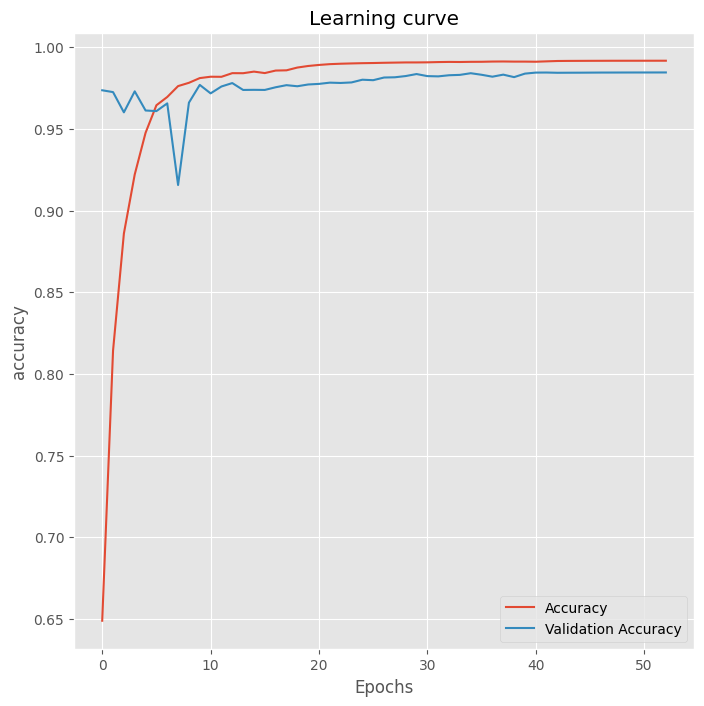

In [ ]:
# Modifying the code for a single output
plt.figure(figsize=(8, 8))
plt.title("Learning curve")
# Assuming results.history['loss'] and results.history['val_loss'] correspond to the single output loss
plt.plot(results.history["accuracy"], label="Accuracy")
plt.plot(results.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("accuracy")
plt.legend()
plt.show()


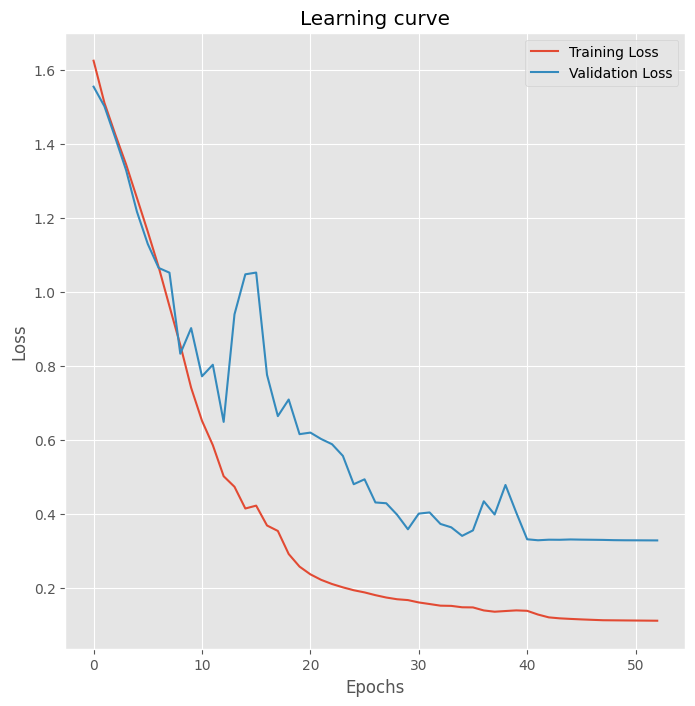

In [ ]:
# Modifying the code for a single output
plt.figure(figsize=(8, 8))
plt.title("Learning curve")
# Assuming results.history['loss'] and results.history['val_loss'] correspond to the single output loss
plt.plot(results.history["loss"], label="Training Loss")
plt.plot(results.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [ ]:
from keras.models import load_model
model.load_weights('/content/drive/MyDrive/LFA_Net_updated_DMID_22_1_26.weights.h5')

In [ ]:
preds_test = model.predict(X_valid, verbose=1)

2/2 ━━━━━━━━━━━━━━━━━━━━ 14s 5s/step


In [ ]:
preds_val = np.asarray(preds_test)

In [ ]:
for i in range(len(preds_val)):
  plt.imsave("/content/drive/MyDrive/LFA_Net_updated_DMID_22_1_26/segmentation/"+str(i+1)+".png",preds_val[i,:,:,0],cmap='gray') # binary segmenation
  plt.imsave("/content/drive/MyDrive/LFA_Net_updated_DMID_22_1_26/masks/"+str(i+1)+".png",y[i,:,:,0],cmap='gray') # binary mask

In [ ]:
im_width = 256
im_height = 256
path_train = '/content/TestDataset/images'

In [ ]:
import os
import numpy as np
from keras.utils import load_img, img_to_array
from skimage.transform import resize

def get_data(path, im_height, im_width):
    images_paths = os.path.join(path, 'images')
    masks_paths = os.path.join(path, 'masks')

    valid_exts = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

    # Filter files to include only valid image files
    images_ids = sorted([
        f for f in os.listdir(images_paths)
        if os.path.isfile(os.path.join(images_paths, f)) and f.lower().endswith(valid_exts)
    ])
    masks_ids = sorted([
        f for f in os.listdir(masks_paths)
        if os.path.isfile(os.path.join(masks_paths, f)) and f.lower().endswith(valid_exts)
    ])

    X = np.zeros((len(images_ids), im_height, im_width, 3), dtype=np.float32)
    y = np.zeros((len(masks_ids), im_height, im_width, 1), dtype=np.float32)

    print('Getting and resizing images ... ')
    for n in range(len(images_ids)):
        # Load and resize image
        img = load_img(os.path.join(images_paths, images_ids[n]), color_mode='rgb')
        x_img = img_to_array(img)
        x_img = resize(x_img, (im_height, im_width, 3), mode='constant', preserve_range=True)

        # Load and resize mask
        mask_img = load_img(os.path.join(masks_paths, masks_ids[n]), color_mode='grayscale')
        mask = img_to_array(mask_img)
        mask = resize(mask, (im_height, im_width, 1), mode='constant', preserve_range=True)

        # Normalize
        X[n] = x_img / 255.
        y[n] = mask / 255.

    print('Done!')
    return X, y


In [ ]:
X, y = get_data(path_train, im_height=256, im_width=256)

Getting and resizing images ... 
Done!


In [ ]:
# Predict on train, val and test
# preds_train = model.predict(X_train, verbose=1)
preds_val = model.predict(X, verbose=1)

# Threshold predictions
# preds_train_t = (preds_train > 0.5).astype(np.uint8)
# preds_val_t = (preds_val[0]> 0.5).astype(np.uint8)

2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 4s/step


In [ ]:
memory_usage = model.count_params() * 4  # Assuming float32 data type (4 bytes per parameter)
print("Memory Usage: {:.2f} MB".format(memory_usage / 1024 / 1024))  # Divide by 1024 twice to convert from bytes to KB, then KB to MB


Memory Usage: 0.75 MB


In [ ]:
import time
start_time=time.time()
model.predict(X)
end_time=time.time()
duration= end_time-start_time
hours = duration // 3600
minutes = (duration - (hours * 3600)) // 60
seconds = (duration - ((hours * 3600) + (minutes * 60)))
# msg = f"training elapsed time was" {str(hours)} hours, {:4.2f} minutes, {:4.2f} seconds)
print (hours) # print out training duration time
print (minutes)
print (seconds)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
0.0
0.0
0.18998312950134277


In [ ]:
import tensorflow as tf
import numpy as np

# Ensure model is built (run a dummy input once)
dummy_input = tf.random.normal((1, 256, 256, 3))  # adjust to your input shape
_ = model(dummy_input)

total_flops = 0

for layer in model.layers:
    # Skip layers with no weights or undefined outputs
    if not hasattr(layer, 'output') or not hasattr(layer, 'weights'):
        continue

    output_shape = layer.output.shape
    if None in output_shape[1:]:
        # Try to get static shape from a concrete function
        try:
            concrete_func = tf.function(model).get_concrete_function(dummy_input)
            output_shape = model.get_layer(layer.name).output.shape
        except:
            continue

    output_shape = [d for d in output_shape[1:] if d is not None]  # drop batch dim

    if len(output_shape) == 0:
        continue

    # ---- Conv2D ----
    if isinstance(layer, tf.keras.layers.Conv2D):
        kernel_shape = layer.kernel.shape.as_list()
        if None not in kernel_shape:
            H, W, C_out = output_shape
            Kx, Ky, C_in, _ = kernel_shape
            total_flops += H * W * C_out * C_in * Kx * Ky

    # ---- DepthwiseConv2D ----
    elif isinstance(layer, tf.keras.layers.DepthwiseConv2D):
        kernel_shape = layer.depthwise_kernel.shape.as_list()
        if None not in kernel_shape:
            H, W, C_in = output_shape
            Kx, Ky, _ = kernel_shape[:3]
            total_flops += H * W * C_in * Kx * Ky

    # ---- Dense ----
    elif isinstance(layer, tf.keras.layers.Dense):
        kernel_shape = layer.kernel.shape.as_list()
        if None not in kernel_shape:
            total_flops += np.prod(kernel_shape)

    # ---- Approximate Attention ----
    elif "attention" in layer.name.lower():
        try:
            seq_len = np.prod(output_shape[:-1])
            dim = output_shape[-1]
            total_flops += seq_len * (dim ** 2)
        except:
            continue

print(f"Approx Total FLOPs: {total_flops / 1e9:.2f} GFLOPs")


Approx Total FLOPs: 0.39 GFLOPs
